# 第五轮附加市场实验：更晚的赛前信息，不是纯历史算法增益

**通过市场信息升级门槛，冻结推荐为 `context_calibrated_C0.01`。** 在完整2,588场2023比赛上判对 **1727场（66.73%）**，距离70%仍需净增85场正确判断。

这个结果使用供应方称为开盘/赛前最后报价的市场信息。原任务只用赛事开始周及T−21历史；这里的信息通常更晚、来源也不同。**不能把加入市场后的改善归功于仅靠排名、状态和历史交手的模型达到同样效果。**2023已反复查看，本报告是探索性结果；2024–2025未打开。

## 同一全量分母，缺失精确回退

底模固定为第四轮 `add_age_spline_C0.01`，不根据本轮或主第五轮2023成绩换底模。训练阶段使用其2021/2022真实向前OOF概率，2023使用冻结预测。参数选择曾使用这些开发折，因而这些OOF不是一个全新独立测试集。

所有市场模型在无法匹配或双边赔率无效时，**逐行精确回退到该底模**。Opening与closing的缺失位置不同，两个全量分数因此包含不同的市场覆盖成分。

| 年份 | 完整目标 | 匹配 | opening有效 | opening回退 | closing有效 | closing回退 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 2021 | 2388 | 2381 | 2374 | 14 | 0 | 2388 |
| 2022 | 2528 | 2495 | 2480 | 48 | 1859 | 669 |
| 2023 | 2588 | 2502 | 2487 | 101 | 2477 | 111 |

2021没有closing，故跨年可训练候选仅使用opening。Closing只作为独立描述基准，不参与门槛或最终推荐选择。不能仅保留有价格的样本，再把其分数称作完整2,588场成绩。

## 全量比较与70%目标

| 角色/模型 | 正确数 / 2588 | 准确率 | log loss | Brier |
| --- | ---: | ---: | ---: | ---: |
| 固定R4历史：`history_only` | 1696 | 65.53% | 0.609407 | 0.211493 |
| 原始开盘+缺失回退：`opening_market` | 1728 | 66.77% | 0.591583 | 0.204183 |
| 收盘独立描述+缺失回退：`closing_market_descriptive` | 1752 | 67.70% | 0.587718 | 0.202790 |
| 冻结推荐：`context_calibrated_C0.01` | 1727 | 66.73% | 0.593036 | 0.204699 |
| 最佳观察（不更改推荐）：`fusion_calibrated_C0.01` | 1737 | 67.12% | 0.593738 | 0.205052 |

全部开盘候选中的最高观察准确率为 `fusion_calibrated_C0.01`（67.12%，1737场）。含独立closing行的最高观察值为 `closing_market_descriptive`（67.70%，1752场）。**这些观察排序不覆盖冻结选择，也不能把closing的更晚报价条件混同于opening。**全量70%需要至少 **1812场正确**；达到目标本身不等于超过市场或达到SOTA。

![市场信息条件下的完整比赛比较](results/round5/market/market_comparison.png)

## 市场信息贡献与额外算法贡献分开看

冻结推荐相对固定R4历史模型：准确率变化 **+1.20个百分点**，log-loss减少 **+0.016371**。这包含市场带来的额外信息。

相对**原始去水opening+相同缺失回退**：准确率变化 **-0.04个百分点**，log-loss减少 **-0.001453**；准确率变化的配对日期块95%区间为 **[-0.37, +0.28]个百分点**。相对开盘市场的配对区间包含0，不能确认存在额外预测增益。

区间按目标赛事开始日期分块，不校正多轮探索、参数选择及跨日期重复球员依赖。它是对已保存候选的条件描述，不是独立最终检验；Notebook保留全部模型相对历史与opening的区间。

## 冻结选择经过什么检验

共20个固定候选：历史底模、原始opening、固定概率/logit融合，以及三种对称logistic校准。阈值始终为0.5。2021H2在更早2021数据上拟合后选择 `fusion_calibrated_C0.01`；2022检查其准确率 **68.55%** 对历史 **67.13%**，提升 **+1.42个百分点**（要求至少0.50）；候选log loss **0.584323**，历史 **0.594658**，允许最多增加0.005。

之后用2021H2+2022时间外预测重选固定候选，并只用2021–2022拟合最终校准。冻结后才计算本轮2023成绩。2022本身也曾被前轮使用，所以这个门槛是明确的探索性决策规则，不是恢复了独立性。

## 来源、限制与复跑

数据：[Valuebetennis公开CSV](https://www.valuebetennis.com/en/donnees.htm)，[CC BY4.0](https://creativecommons.org/licenses/by/4.0/)。仅下载2021–2023。开盘与收盘字段没有逐条报价采集时间，只有供应方的赛前定义；无法独立证明每笔报价在规定预测时刻已公开。单一来源的历史导出不等于多家公司市场共识，也不构成投注收益结论。匹配只用身份、日期、赛事、场地及轮次，不用胜者或比分。

[来源与匹配审计](docs/research/round5_market.md) · [独立市场协议](docs/research/round5_market_protocol.md) · [执行Notebook](round5_market.ipynb) · [HTML](round5_market.html)

```sh
.venv/bin/python -m scripts.train_market_round5
.venv/bin/python -m scripts.report_market_round5
```

保留主T−21第五轮与本市场分支两个结论。最终测试应按各自冻结协议独立进行，继续保留原始opening、closing和历史模型对照。


## 全部已冻结候选的完整2023比较

Closing不参与选择；额外正确数以全量1812门槛计算。

,model,description,role,matches,correct,accuracy,mean_log_loss,brier,additional_correct_for_70,accuracy_gain_vs_opening_pp,log_loss_reduction_vs_opening
0,closing_market_descriptive,Raw closing market + fallback (descriptive),Later closing benchmark; never selected,2588,1752,0.676971,0.587718,0.202790,60,0.927357,0.003865
1,fusion_calibrated_C0.01,fusion calibrated C0.01,Exploratory fixed opening candidate,2588,1737,0.671175,0.593738,0.205052,75,0.347759,-0.002155
2,fusion_calibrated_C0.1,fusion calibrated C0.1,Exploratory fixed opening candidate,2588,1735,0.670402,0.592351,0.204588,77,0.270479,-0.000768
3,context_calibrated_C10,context calibrated C10,Exploratory fixed opening candidate,2588,1731,0.668856,0.591832,0.204339,81,0.115920,-0.000249
4,context_calibrated_C1,context calibrated C1,Exploratory fixed opening candidate,2588,1731,0.668856,0.591834,0.204342,81,0.115920,-0.000251
5,logit_blend_market0.75,logit blend market0.75,Exploratory fixed opening candidate,2588,1731,0.668856,0.593064,0.204760,81,0.115920,-0.001481
6,probability_blend_market0.75,probability blend market0.75,Exploratory fixed opening candidate,2588,1731,0.668856,0.593116,0.204768,81,0.115920,-0.001533
7,logit_blend_market0.5,logit blend market0.5,Exploratory fixed opening candidate,2588,1731,0.668856,0.596526,0.206174,81,0.115920,-0.004943
8,probability_blend_market0.5,probability blend market0.5,Exploratory fixed opening candidate,2588,1731,0.668856,0.596561,0.206181,81,0.115920,-0.004978
9,market_calibrated_C0.1,market calibrated C0.1,Exploratory fixed opening candidate,2588,1728,0.667697,0.591514,0.204246,84,0.000000,0.000069


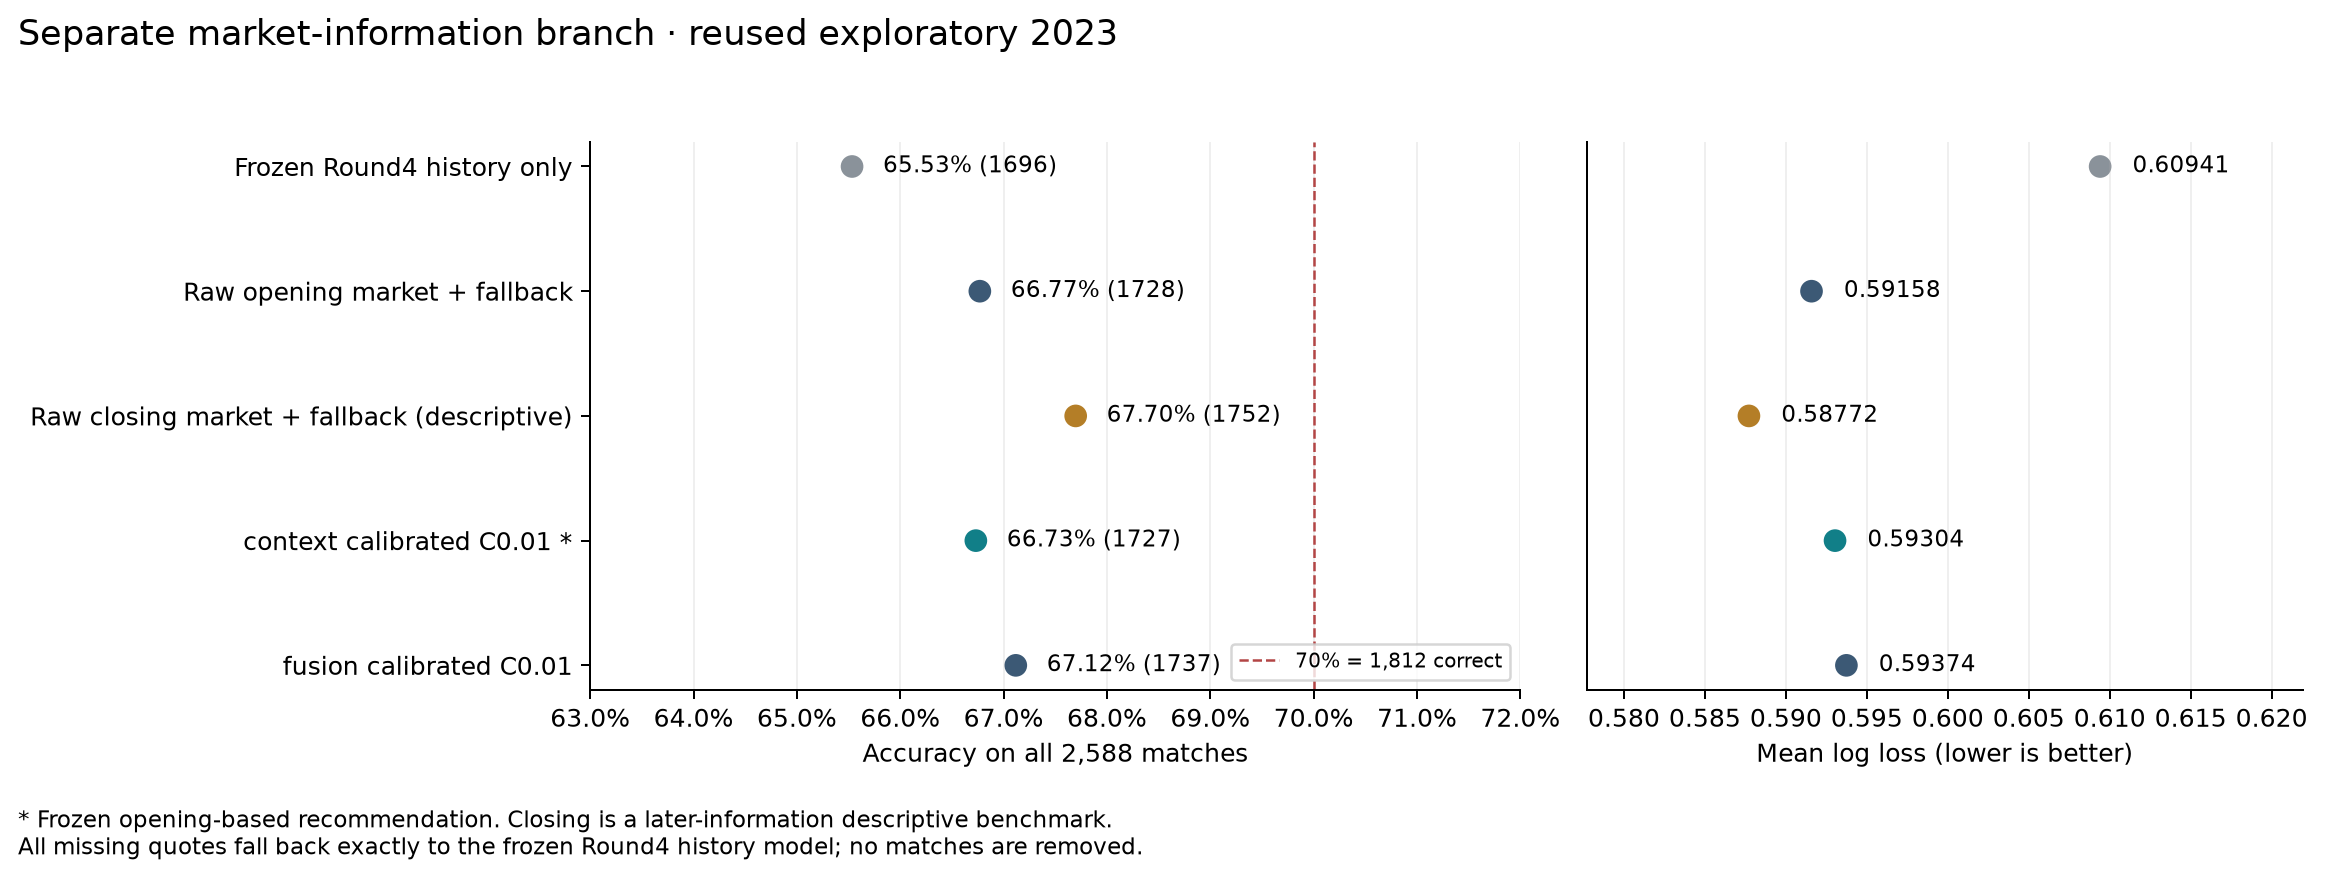

In [1]:
from IPython.display import display, Image
import pandas as pd
from scripts.report_market_round5 import load_results, comparison_table, coverage_table, intervals_table, OUT
data=load_results()
pd.set_option('display.max_columns',None)
pd.set_option('display.precision',6)
display(comparison_table(data))
display(Image(filename=str(OUT/'market_comparison.png')))

## 报价覆盖、匹配状态和缺失回退

此处是数据覆盖，不是删减后的性能。

In [2]:
display(coverage_table(data))
display(data['links'].groupby(['season','status']).size().rename('matches').reset_index())
print('Every missing opening/closing forecast was checked against exact frozen history fallback.')

,season,targets,matched,opening_available,closing_available,opening_missing_fallback,closing_missing_fallback
0,2021,2388,2381,2374,0,14,2388
1,2022,2528,2495,2480,1859,48,669
2,2023,2588,2502,2487,2477,101,111


,season,status,matches
0,2021,matched,2381
1,2021,name_unmatched_or_ambiguous,3
2,2021,no_pair_date_surface_round_candidate,4
3,2022,matched,2495
4,2022,name_unmatched_or_ambiguous,31
5,2022,no_pair_date_surface_round_candidate,2
6,2023,matched,2502
7,2023,name_unmatched_or_ambiguous,59
8,2023,no_pair_date_surface_round_candidate,27


Every missing opening/closing forecast was checked against exact frozen history fallback.


## 全部时间外候选与2022门槛

H2选择、2022门槛、再pool重选；不使用2023选择。

In [3]:
display(data['cv'].sort_values(['accuracy','mean_log_loss'],ascending=[False,True]))
display(pd.DataFrame([data['frozen']['procedure_gate']]))

,name,family,accuracy,mean_log_loss,2021H2_accuracy,2021H2_log_loss,2022_accuracy,2022_log_loss
16,context_calibrated_C0.01,context_calibrated,0.683629,0.588648,0.670692,0.606939,0.688291,0.582057
18,context_calibrated_C1,context_calibrated,0.683338,0.586330,0.669594,0.603683,0.688291,0.580077
13,fusion_calibrated_C0.1,fusion_calibrated,0.683338,0.586368,0.668496,0.603951,0.688687,0.580032
15,fusion_calibrated_C10,fusion_calibrated,0.683047,0.585961,0.670692,0.603557,0.687500,0.579620
19,context_calibrated_C10,context_calibrated,0.683047,0.586381,0.669594,0.603684,0.687896,0.580146
14,fusion_calibrated_C1,fusion_calibrated,0.682757,0.585991,0.670692,0.603581,0.687104,0.579652
11,market_calibrated_C10,market_calibrated,0.682757,0.586243,0.667398,0.603721,0.688291,0.579945
10,market_calibrated_C1,market_calibrated,0.682757,0.586280,0.667398,0.603751,0.688291,0.579985
1,opening_market,opening,0.682757,0.586523,0.667398,0.603684,0.688291,0.580339
9,market_calibrated_C0.1,market_calibrated,0.682757,0.586719,0.667398,0.604191,0.688291,0.580423


,procedure,early_selected,reference_2022_accuracy,candidate_2022_accuracy,accuracy_improvement,required_accuracy_improvement,reference_2022_loss,candidate_2022_loss,allowed_loss_increase,selection_fold,gate_fold
0,adopt_market_information,fusion_calibrated_C0.01,0.671282,0.685522,0.014241,0.005,0.594658,0.584323,0.005,2021H2,2022


## 相对历史与原始opening的条件不确定性

日期块区间不能消除已反复查看2023或多轮选择带来的不确定性。

In [4]:
display(intervals_table(data))
assert data['summary']['final_test_evaluated'] is False
print('Separate market-information regime; 2024–2025 remains unopened.')

,model,accuracy_gain_vs_history_pp,history_accuracy_lower95_pp,history_accuracy_upper95_pp,log_loss_reduction_vs_history,history_loss_lower95,history_loss_upper95,accuracy_gain_vs_opening_pp,opening_accuracy_lower95_pp,opening_accuracy_upper95_pp
0,history_only,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-1.236476,-2.390045,-0.148864
1,opening_market,1.236476,0.148864,2.390045,0.017824,0.011887,0.023754,0.000000,0.000000,0.000000
2,probability_blend_market0.25,0.579598,0.079868,1.038502,0.007476,0.005740,0.009293,-0.656878,-1.796603,0.419468
3,probability_blend_market0.5,1.352396,0.547811,2.173976,0.012846,0.009604,0.016191,0.115920,-0.833739,1.109570
4,probability_blend_market0.75,1.352396,0.497193,2.237826,0.016291,0.011636,0.020980,0.115920,-0.635902,0.829750
5,logit_blend_market0.25,0.618238,0.128622,1.068478,0.007431,0.005771,0.009133,-0.618238,-1.750292,0.454789
6,logit_blend_market0.5,1.352396,0.547811,2.173976,0.012881,0.009667,0.016149,0.115920,-0.833739,1.109570
7,logit_blend_market0.75,1.352396,0.497193,2.237826,0.016343,0.011738,0.021037,0.115920,-0.635902,0.829750
8,market_calibrated_C0.01,1.236476,0.148864,2.390045,0.017180,0.011162,0.023353,0.000000,0.000000,0.000000
9,market_calibrated_C0.1,1.236476,0.148864,2.390045,0.017892,0.011979,0.023884,0.000000,0.000000,0.000000


Separate market-information regime; 2024–2025 remains unopened.
